# LSTM for Text Classification: Sarcasm Detection

**Problem statement:** Predict whether a news headline is sarcastic using the
[News Headlines Dataset for Sarcasm Detection](https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection).
Reuse Day 10's Keras `Tokenizer(num_words=5000)` and
`pad_sequences(..., maxlen=50)` approach. The required model is
`Embedding(5000, 32) → LSTM(32) → Dense(1, activation="sigmoid")`;
train for exactly **5 epochs** and report held-out test accuracy.
The only architecture change from Day 10 is replacing `SimpleRNN(32)` with `LSTM(32)`. No additional layers, dropout, or bidirectionality are added.

**Target:** `is_sarcastic` (0 = not sarcastic, 1 = sarcastic).
**Input:** headline text only. The model uses a sigmoid output and binary
cross-entropy because the dataset has two classes. With more than two classes,
use `Dense(n_classes, activation="softmax")` and sparse categorical
cross-entropy with integer labels.

**Data choice:** Use `Sarcasm_Headlines_Dataset_v2.json` alone. Do not concatenate
it with the overlapping original version. Drop `article_link`, which could
reveal the source website rather than headline language. Retain only `text`
and `label` for model training; engineered features live in a separate EDA dataframe.

This notebook includes full inspection, missing/duplicate/anomaly checks,
four labelled charts, four engineered EDA features with rationale, and five
data-grounded insight bullets. Run every cell in order. On Kaggle, attach
the linked dataset; locally/Colab, place the v2 JSON file beside the notebook
or in `data/`, or allow KaggleHub to download it. If needed, install dependencies
with `%pip install tensorflow pandas scikit-learn matplotlib kagglehub`.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["OMP_NUM_THREADS"] = "1"

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
output_dir = Path("lstm_sarcasm_results")
output_dir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__, "pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

TensorFlow: 2.20.0
NumPy: 2.2.6 pandas: 3.0.6 scikit-learn: 1.9.1


## 1. Initial dataframe inspection — R1

Inspect shape, sample rows, dtypes/info, all-column descriptive statistics,
missing values, blank text, duplicate text, and label values before cleaning.
The source is newline-delimited JSON, so `pd.read_json(..., lines=True)` is used.

In [2]:
filename = "Sarcasm_Headlines_Dataset_v2.json"
candidates = [Path(filename), Path("data") / filename]
if Path("/kaggle/input").exists():
    candidates = sorted(Path("/kaggle/input").rglob(filename)) + candidates
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection"))
    data_path = next(dataset_dir.rglob(filename))

raw = pd.read_json(data_path, lines=True)
df = raw[["headline", "is_sarcastic"]].rename(columns={"headline": "text", "is_sarcastic": "label"}).copy()
raw_rows = len(df)
print("Dataset file:", filename)
print("Raw source shape:", raw.shape)
print("Retained dataframe shape:", df.shape)
display(df.head())
print("Dtypes:")
print(df.dtypes)
print("Dataframe info:")
df.info()
print("Describe all retained columns:")
display(df.describe(include="all"))
missing_before = df.isna().sum()
blank_text_rows = int(df["text"].fillna("").str.strip().eq("").sum())
print("Missing values before cleaning:")
print(missing_before)
print("Blank text rows:", blank_text_rows)
print("Exact duplicate texts:", int(df.duplicated(subset=["text"]).sum()))
print("Labels:", sorted(df["label"].dropna().unique()))

Dataset file: Sarcasm_Headlines_Dataset_v2.json
Raw source shape: (28619, 3)
Retained dataframe shape: (28619, 2)


,text,label
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1


Dtypes:
text       str
label    int64
dtype: object
Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    28619 non-null  str  
 1   label   28619 non-null  int64
dtypes: int64(1), str(1)
memory usage: 447.3 KB
Describe all retained columns:


,text,label
count,28619,28619.000000
unique,28503,NaN
top,"'no way to prevent this,' says only nation whe...",NaN
freq,12,NaN
mean,NaN,0.476397
std,NaN,0.499451
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


Missing values before cleaning:
text     0
label    0
dtype: int64
Blank text rows: 0
Exact duplicate texts: 116
Labels: [np.int64(0), np.int64(1)]


**Inspection interpretation:** The v2 source contains **28,619 rows × 3 columns**.
Keeping only headline text and its target produces **28,619 × 2**. Text is a
string column and the label is numeric with valid values **0 and 1**; `info()`
shows no missing values in either retained column. There are **0 blank texts**
and **116 exact duplicate headlines**. The text section of `describe(include="all")`
shows repeated headlines, while its numeric section summarizes the binary target.
No text/label imputation is needed; remove duplicates before splitting.

In [3]:
df = df.dropna(subset=["text", "label"])
df = df[df["text"].str.strip().ne("")].copy()
conflicting_texts = df.groupby("text")["label"].nunique().gt(1)
assert not conflicting_texts.any(), "Inspect conflicting labels before proceeding"
assert set(df["label"].unique()) == {0, 1}
duplicates_removed = int(df.duplicated(subset=["text"]).sum())
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
df["label"] = df["label"].astype("int32")
assert df.columns.tolist() == ["text", "label"]
label_names = {0: "not sarcastic", 1: "sarcastic"}
print(f"Raw rows: {raw_rows}; duplicates removed: {duplicates_removed}; retained: {len(df)}")
print(df["label"].value_counts().rename(index=label_names))
display(df.head())

Raw rows: 28619; duplicates removed: 116; retained: 28503
label
not sarcastic    14951
sarcastic        13552
Name: count, dtype: int64


,text,label
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1


## 2. Engineer and inspect EDA features — R4

Create these features in **`eda_df`**. They support interpretation of the
dataset and do not become extra inputs to the required neural model.

| Feature | Definition | Rationale |
|---|---|---|
| `message_length` | Number of characters including spaces | Measures headline length and supports anomaly detection. |
| `word_count` | Number of whitespace-separated words | Measures verbosity; complements character length. |
| `punctuation_count` | Number of characters other than word characters or whitespace | Measures punctuation style that may differ between headline classes. |
| `has_question` | 1 when the headline contains a literal `?`, otherwise 0 | Flags a question-style headline so its class association can be inspected. |

Whitespace word counts can differ from Keras token counts. These features
describe associations in this sample; none is assumed to determine sarcasm.

In [4]:
eda_df = df.copy()
eda_df["message_length"] = eda_df["text"].str.len()
eda_df["word_count"] = eda_df["text"].str.split().str.len()
eda_df["punctuation_count"] = eda_df["text"].str.count(r"[^\w\s]")
eda_df["has_question"] = eda_df["text"].str.contains("?", regex=False).astype("int32")
feature_columns = ["message_length", "word_count", "punctuation_count", "has_question"]
assert df.columns.tolist() == ["text", "label"]
assert eda_df[feature_columns].notna().all().all()
assert eda_df["message_length"].gt(0).all() and eda_df["word_count"].gt(0).all()
assert eda_df["punctuation_count"].ge(0).all()
print("Engineered feature sample:")
display(eda_df[["label"] + feature_columns].head(10))
print("Feature dtypes:")
print(eda_df[feature_columns].dtypes)
print("Describe engineered features:")
display(eda_df[feature_columns].describe())
feature_by_label = eda_df.groupby("label").agg(
    headlines=("text", "size"),
    median_characters=("message_length", "median"),
    mean_characters=("message_length", "mean"),
    median_words=("word_count", "median"),
    mean_punctuation=("punctuation_count", "mean"),
    question_headlines=("has_question", "sum"),
    question_rate=("has_question", "mean"),
).rename(index=label_names)
display(feature_by_label)

Engineered feature sample:


,label,message_length,word_count,punctuation_count,has_question
0,1,61,8,0,0
1,0,79,13,2,0
2,0,49,7,1,0
3,1,52,8,0,0
4,1,61,9,2,0
5,0,20,3,0,0
6,0,42,9,0,0
7,1,88,13,2,0
8,1,73,12,0,0
9,0,34,6,0,0


Feature dtypes:
message_length       int64
word_count           int64
punctuation_count    int64
has_question         int32
dtype: object
Describe engineered features:


,message_length,word_count,punctuation_count,has_question
count,28503.000000,28503.000000,28503.000000,28503.000000
mean,62.380241,10.060871,1.125039,0.028944
std,20.706474,3.385275,1.338981,0.167653
min,7.000000,2.000000,0.000000,0.000000
25%,49.000000,8.000000,0.000000,0.000000
50%,62.000000,10.000000,1.000000,0.000000
75%,75.000000,12.000000,2.000000,0.000000
max,926.000000,151.000000,29.000000,1.000000


,headlines,median_characters,mean_characters,median_words,mean_punctuation,question_headlines,question_rate
label,,,,,,,
not sarcastic,14951,61.0,59.615143,10.0,1.300983,726,0.048559
sarcastic,13552,64.0,65.430785,10.0,0.930933,99,0.007305


## 3. Length outliers and other anomalies — R2

Check both tails with the **1.5 × IQR** rule, display the shortest/longest
examples, and check missing features, zero-length text, zero-word text, and
conflicting labels. A length outlier is not automatically an invalid headline.

In [5]:
q1, q3 = eda_df["message_length"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
short_count = int(eda_df["message_length"].lt(lower_bound).sum())
long_count = int(eda_df["message_length"].gt(upper_bound).sum())
outlier_count = short_count + long_count
print(f"Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}; bounds=[{lower_bound:.1f}, {upper_bound:.1f}] characters")
print(f"Short outliers: {short_count}; long outliers: {long_count}; total: {outlier_count} ({outlier_count / len(df):.2%})")
print("Character-length range:", eda_df["message_length"].min(), "to", eda_df["message_length"].max())
print("Zero-length texts:", int(eda_df["message_length"].eq(0).sum()))
print("Zero-word texts:", int(eda_df["word_count"].eq(0).sum()))
print("Conflicting labels:", int(conflicting_texts.sum()))
print("Missing engineered feature values:", int(eda_df[feature_columns].isna().sum().sum()))
with pd.option_context("display.max_colwidth", 1000):
    print("Shortest headlines:")
    display(eda_df.nsmallest(3, "message_length")[["text", "label", "message_length", "word_count"]])
    print("Longest headlines:")
    display(eda_df.nlargest(3, "message_length")[["text", "label", "message_length", "word_count"]])

Q1=49.0, Q3=75.0, IQR=26.0; bounds=[10.0, 114.0] characters
Short outliers: 9; long outliers: 295; total: 304 (1.07%)
Character-length range: 7 to 926
Zero-length texts: 0
Zero-word texts: 0
Conflicting labels: 0
Missing engineered feature values: 0
Shortest headlines:


,text,label,message_length,word_count
28263,bye bye,0,7,2
10098,top cute,1,8,2
11859,déjà vu?,0,8,2


Longest headlines:


,text,label,message_length,word_count
7288,"hot wheels ranked number one toy for rolling down ramp, knocking over dominoes that send marble down a funnel, dropping onto teeter-totter that yanks on string, causing pulley system to raise wooden block, propelling series of twine rollers that unwind spring, launching tennis ball across room, inching tire down slope until it hits power switch, activating table fan that blows toy ship with nail attached to it across kiddie pool, popping water balloon that fills cup, weighing down lever that forces basketball down track, nudging broomstick on axis to rotate, allowing golf ball to roll into sideways coffee mug, which tumbles down row of hardcover books until handle catches hook attached to lever that causes wooden mallet to slam down on serving spoon, catapulting small ball into cup attached by ribbon to lazy susan, which spins until it pushes d battery down incline plane, tipping over salt shaker to season omelet",1,926,151
2145,"maya angelou, poet, author, civil rights activist, and—holy cow—tony award–nominated actress, college professor, magazine editor, streetcar conductor—really? streetcar conductor? wow—calypso singer, nightclub performer, and foreign journalist, dead at 86",1,254,29
16539,"'12 years a slave,' 'captain phillips,' 'american hustle,' 'wolf of wall street,' 'blue jasmine,' 'dallas buyers club,' 'her,' 'nebraska,' 'before midnight,' and 'philomena' all written during same continuing education screenwriting class",1,238,31


**Decision:** Q1 is **49**, Q3 is **75**, and the IQR bounds are **10–114
characters**. There are **9 shorter** and **295 longer** headlines (**304
total, 1.07%**); lengths range from **7 to 926**. The longest headline is a
deliberately elaborate toy-chain-reaction description, so its unusual length
is plausible source text. No empty/zero-word texts, conflicting labels, or
missing features remain. **Retain all 304 flagged headlines and do not cap
character or word-count features:** deleting them solely on length could
discard valid sarcasm styles. Model inputs are separately padded/truncated
to exactly **50 Keras tokens**, as required. EDA does not select or tune the model.

## 4. Four labelled EDA charts — R3

Use all **28,503 unique headlines**. Blue denotes not sarcastic and orange
denotes sarcastic. The histogram uses a log count axis to keep rare length
extremes visible; the boxplot also includes its outlier points.

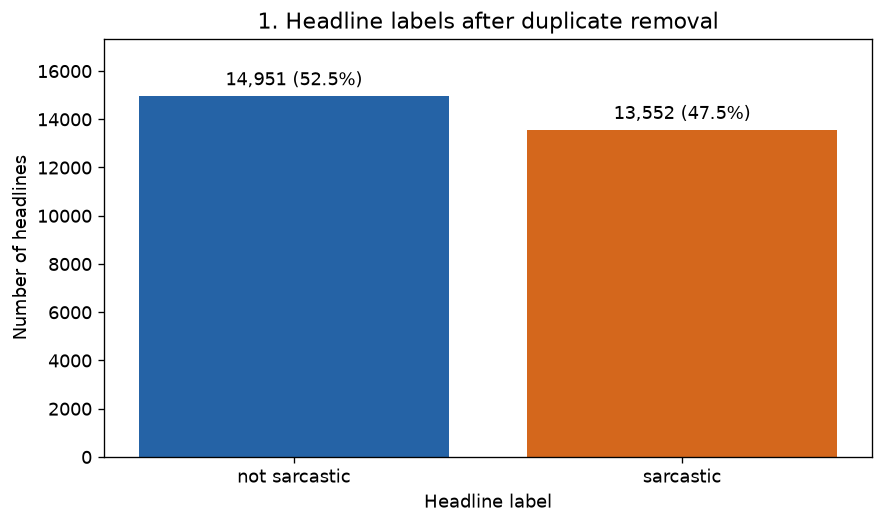

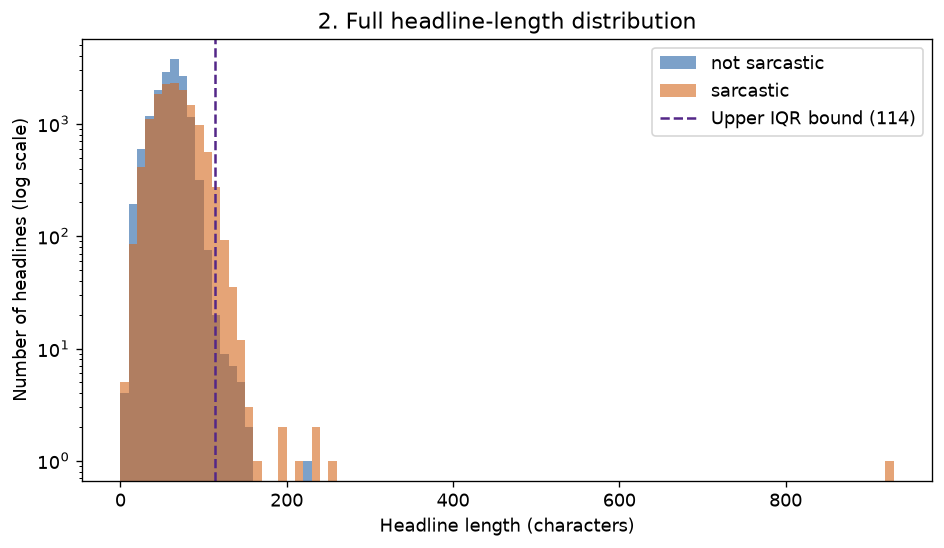

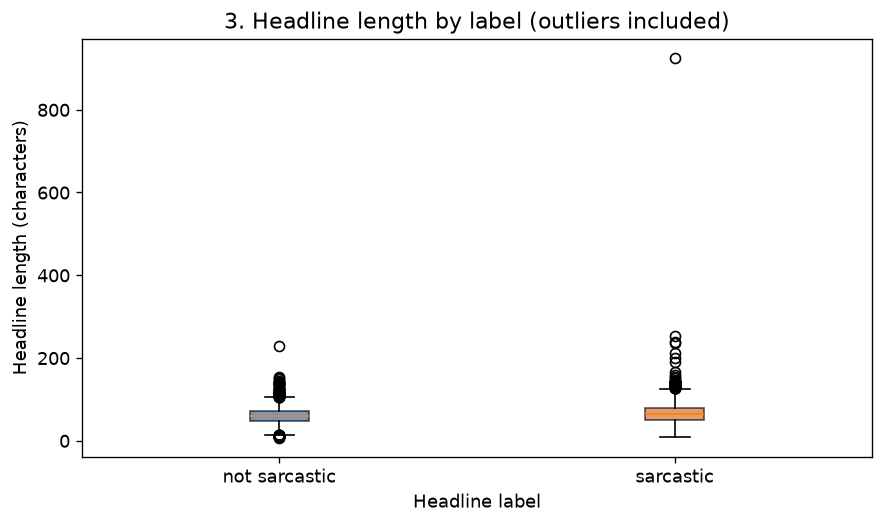

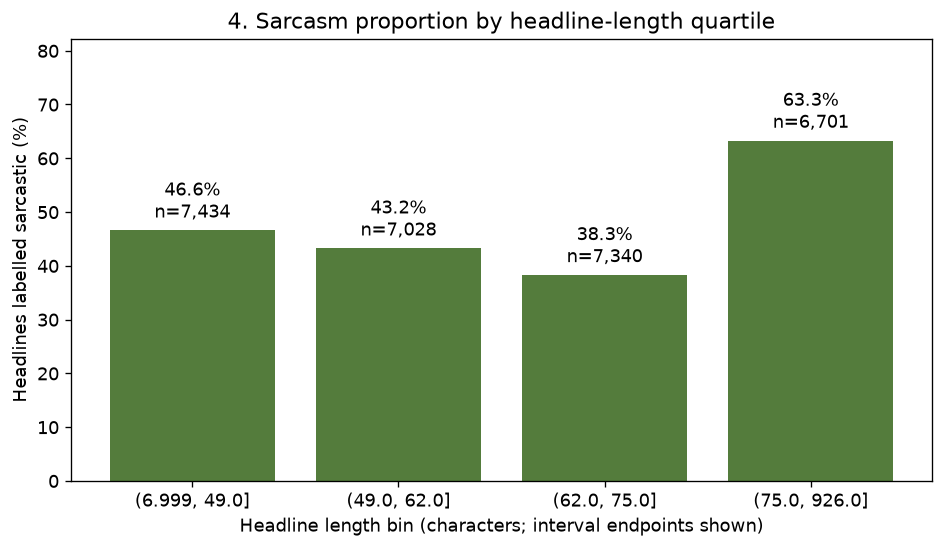

,headlines,sarcasm_rate
length_bin,,
"(6.999, 49.0]",7434,0.465833
"(49.0, 62.0]",7028,0.432413
"(62.0, 75.0]",7340,0.382834
"(75.0, 926.0]",6701,0.632741


In [6]:
colors = {0: "#2563a6", 1: "#d4671c"}
counts = eda_df["label"].value_counts().reindex([0, 1])

# 1. Label count plot.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar([label_names[i] for i in [0, 1]], counts.values, color=[colors[0], colors[1]])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(df):.1%})" for n in counts], padding=4)
ax.set(title="1. Headline labels after duplicate removal", xlabel="Headline label", ylabel="Number of headlines")
ax.set_ylim(0, counts.max() * 1.16)
fig.tight_layout()
fig.savefig(output_dir / "01_label_counts.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Message-length histogram; full range and log count scale.
fig, ax = plt.subplots(figsize=(8, 4.7))
bins = np.arange(0, eda_df["message_length"].max() + 11, 10)
for label in [0, 1]:
    ax.hist(eda_df.loc[eda_df["label"].eq(label), "message_length"], bins=bins,
            color=colors[label], alpha=0.60, label=label_names[label])
ax.axvline(upper_bound, color="#542788", linestyle="--", label=f"Upper IQR bound ({upper_bound:.0f})")
ax.set_yscale("log")
ax.set(title="2. Full headline-length distribution", xlabel="Headline length (characters)", ylabel="Number of headlines (log scale)")
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "02_length_histogram.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Length by label; outlier points retained.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
box = ax.boxplot([eda_df.loc[eda_df["label"].eq(label), "message_length"] for label in [0, 1]],
                 patch_artist=True, showfliers=True)
for patch, label in zip(box["boxes"], [0, 1]):
    patch.set_facecolor(colors[label])
    patch.set_alpha(0.65)
ax.set_xticks([1, 2])
ax.set_xticklabels([label_names[0], label_names[1]])
ax.set(title="3. Headline length by label (outliers included)", xlabel="Headline label", ylabel="Headline length (characters)")
fig.tight_layout()
fig.savefig(output_dir / "03_length_by_label_boxplot.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# 4. Length-label association by length quartile.
length_bins = pd.qcut(eda_df["message_length"], q=4, duplicates="drop")
association = eda_df.assign(length_bin=length_bins).groupby("length_bin", observed=True).agg(
    headlines=("label", "size"), sarcasm_rate=("label", "mean")
)
fig, ax = plt.subplots(figsize=(8, 4.7))
bars = ax.bar(association.index.astype(str), association["sarcasm_rate"] * 100, color="#547c3c")
ax.bar_label(bars, labels=[f"{row.sarcasm_rate:.1%}\nn={int(row.headlines):,}" for row in association.itertuples()], padding=4)
ax.set(title="4. Sarcasm proportion by headline-length quartile", xlabel="Headline length bin (characters; interval endpoints shown)", ylabel="Headlines labelled sarcastic (%)")
ax.set_ylim(0, min(100, association["sarcasm_rate"].max() * 100 * 1.3))
fig.tight_layout()
fig.savefig(output_dir / "04_length_label_association.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(association)

eda_summary = {
    "source_file": filename, "source_shape": list(raw.shape),
    "retained_input_columns": df.columns.tolist(), "clean_rows": len(df),
    "missing_values_before": int(missing_before.sum()), "blank_text_rows": blank_text_rows,
    "duplicates_removed": duplicates_removed,
    "class_counts": {label_names[i]: int(counts[i]) for i in [0, 1]},
    "engineered_features": feature_columns,
    "length_q1": float(q1), "length_q3": float(q3),
    "length_iqr_lower": float(lower_bound), "length_iqr_upper": float(upper_bound),
    "short_outliers": short_count, "long_outliers": long_count, "total_outliers": outlier_count,
    "length_min": int(eda_df["message_length"].min()), "length_max": int(eda_df["message_length"].max()),
    "outlier_policy": "Retain all flagged messages; no character/word-count capping; model maxlen=50 tokens.",
    "chart_files": ["01_label_counts.png", "02_length_histogram.png", "03_length_by_label_boxplot.png", "04_length_label_association.png"],
}
(output_dir / "eda_summary.json").write_text(json.dumps(eda_summary, indent=2))
feature_by_label.to_csv(output_dir / "features_by_label.csv")
association.to_csv(output_dir / "length_label_association.csv")
assert len(raw) == 28619 and len(df) == 28503 and duplicates_removed == 116
assert counts.to_dict() == {0: 14951, 1: 13552}
assert q1 == 49 and q3 == 75 and short_count == 9 and long_count == 295
assert feature_by_label.loc["not sarcastic", "median_characters"] == 61
assert feature_by_label.loc["sarcastic", "median_characters"] == 64
assert feature_by_label["median_words"].eq(10).all()
assert feature_by_label.loc["not sarcastic", "question_headlines"] == 726
assert feature_by_label.loc["sarcastic", "question_headlines"] == 99

## 5. Five data-grounded insights — R5

- **Cleaning:** The v2 file has **28,619** rows, **0 missing text/label values**, and **0 blank headlines**. Removing **116 exact duplicate headlines (0.41%)** leaves **28,503** unique examples, with no identical text crossing the train/test split.
- **Class balance (chart 1):** There are **14,951 not-sarcastic headlines (52.45%)** and **13,552 sarcastic headlines (47.55%)**. The classes are fairly balanced, though a majority-class baseline and stratified split still provide useful evaluation context.
- **Length and verbosity (charts 2–4 and feature table):** Median character length is **61** for not sarcastic versus **64** for sarcastic; both classes have median **10 words**. Length distributions overlap, so length alone cannot reliably identify sarcasm.
- **Anomalies (IQR check and charts 2–3):** Character-length bounds of **10–114** flag **9 short + 295 long = 304 headlines (1.07%)**, with a full range of **7–926 characters**. They are retained as plausible headline text; the model separately enforces **50 tokens**, without capping the EDA features.
- **Question feature:** A question mark occurs in **726 of 14,951 not-sarcastic headlines (4.86%)** but only **99 of 13,552 sarcastic headlines (0.73%)**. Question-style headlines are more frequent in the not-sarcastic class in this source sample; this is an association, not a rule or causal claim.

The assertions in the EDA cell verify the counts behind these bullets.
EDA describes this sample; the architecture and training settings remain fixed.

## 6. Split and tokenize — same approach as Day 10

Use an 80/20 stratified split with `random_state=42`. Learn the vocabulary
**only from training headlines** using Keras `Tokenizer(num_words=5000,
oov_token="<OOV>")`. The tokenizer lowercases and filters punctuation using its
defaults, matching Day 10; no TF-IDF, stemming, extra model features or source URLs are used.

In [7]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.20, random_state=SEED, stratify=df["label"]
)
assert set(X_train_text).isdisjoint(set(X_test_text))
print(f"Training headlines: {len(X_train_text)}; test headlines: {len(X_test_text)}")
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)
train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

Training headlines: 22802; test headlines: 5701


## 7. Pad or truncate every sequence to exactly 50 tokens

Short sequences receive leading zeros; sequences longer than 50 keep their
last 50 tokens. One `maxlen=50` setting handles all rows. Index 0 is padding,
index 1 is OOV, and retained token indices are below 5000, matching the embedding.

In [8]:
X_train = pad_sequences(train_sequences, maxlen=50, padding="pre", truncating="pre")
X_test = pad_sequences(test_sequences, maxlen=50, padding="pre", truncating="pre")
y_train = y_train.to_numpy(dtype="int32")
y_test = y_test.to_numpy(dtype="int32")
assert X_train.shape == (len(y_train), 50) and X_test.shape == (len(y_test), 50)
assert 0 <= X_train.min() and X_train.max() < 5000
assert 0 <= X_test.min() and X_test.max() < 5000
print("Train shape:", X_train.shape, "test shape:", X_test.shape)
print("Sequences longer than 50 tokens before truncation:",
      sum(len(sequence) > 50 for sequence in train_sequences + test_sequences))

Train shape: (22802, 50) test shape: (5701, 50)
Sequences longer than 50 tokens before truncation: 1


## 8. Build the exact LSTM model

A 5,000-entry embedding maps tokens to 32-value vectors. A single 32-unit
LSTM passes its final output to one sigmoid neuron estimating sarcasm
probability. The required main model is the Day 10 architecture with only
SimpleRNN swapped for LSTM; the optional copy swaps only LSTM for GRU.

In [9]:
model = Sequential([
    Embedding(5000, 32),
    LSTM(32),
    Dense(1, activation="sigmoid")
])
model.build(input_shape=(None, 50))
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()
assert [type(layer).__name__ for layer in model.layers] == ["Embedding", "LSTM", "Dense"]
assert model.count_params() == 168353

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train for exactly five epochs

Keep Adam, binary cross-entropy, batch size **64**, seed **42**, and exactly
**5 epochs**, matching Day 10's training setup. Small TensorFlow dataset thread
pools support reliable CPU execution. No early stopping, validation using the
test set, or tuning against test results is performed.

In [10]:
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
train_ds = train_ds.batch(64).with_options(options)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(64).with_options(options)
history = model.fit(train_ds, epochs=5, verbose=2)
assert len(history.epoch) == 5

Epoch 1/5


357/357 - 3s - 9ms/step - accuracy: 0.7844 - loss: 0.4406


Epoch 2/5


357/357 - 2s - 7ms/step - accuracy: 0.8808 - loss: 0.2824


Epoch 3/5


357/357 - 2s - 7ms/step - accuracy: 0.9024 - loss: 0.2402


Epoch 4/5


357/357 - 2s - 7ms/step - accuracy: 0.9126 - loss: 0.2183


Epoch 5/5


357/357 - 2s - 7ms/step - accuracy: 0.9284 - loss: 0.1861


## 10. Held-out test accuracy

Predict sarcastic at probability ≥ 0.5. Report accuracy plus a majority-class
baseline, confusion matrix and per-class precision/recall/F1. The fixed holdout
measures performance within this source dataset; it is not an estimate for
every news source. Small floating-point differences can change results across runs.

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0).reshape(-1)
y_pred = (probabilities >= 0.5).astype("int32")
assert np.isclose(test_accuracy, accuracy_score(y_test, y_pred), atol=1e-6)
baseline_accuracy = float(np.mean(y_test == int(np.bincount(y_train).argmax())))
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy:.2%})")
print(f"Majority-class baseline: {baseline_accuracy:.4f} ({baseline_accuracy:.2%})")
print("Confusion matrix (rows=actual, columns=predicted; order=not sarcastic, sarcastic):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=[label_names[0], label_names[1]], digits=4, zero_division=0))
summary = {
    "dataset": "rmisra/news-headlines-dataset-for-sarcasm-detection", "source_file": filename,
    "raw_rows": raw_rows, "duplicates_removed": duplicates_removed, "retained_rows": len(df),
    "train_rows": len(X_train), "test_rows": len(X_test), "seed": SEED,
    "num_words": 5000, "maxlen": 50, "epochs": len(history.epoch), "batch_size": 64,
    "recurrent_layer": "LSTM", "model_parameters": model.count_params(),
    "architecture": "Embedding(5000,32) -> LSTM(32) -> Dense(1,sigmoid)",
    "test_accuracy": float(test_accuracy), "test_loss": float(test_loss),
    "majority_baseline_accuracy": baseline_accuracy,
    "confusion_matrix": confusion_matrix(y_test, y_pred, labels=[0, 1]).tolist(),
    "tensorflow_version": tf.__version__,
}
(output_dir / "results_summary.json").write_text(json.dumps(summary, indent=2))
pd.DataFrame(history.history, index=range(1, 6)).rename_axis("epoch").to_csv(output_dir / "training_history.csv")

TEST ACCURACY: 0.8551 (85.51%)
Majority-class baseline: 0.5245 (52.45%)
Confusion matrix (rows=actual, columns=predicted; order=not sarcastic, sarcastic):
[[2632  358]
 [ 468 2243]]
               precision    recall  f1-score   support

not sarcastic     0.8490    0.8803    0.8644      2990
    sarcastic     0.8624    0.8274    0.8445      2711

     accuracy                         0.8551      5701
    macro avg     0.8557    0.8538    0.8544      5701
 weighted avg     0.8554    0.8551    0.8549      5701



## What does the forget gate let an LSTM do?

An LSTM's forget gate learns how much of each value in its previous cell
state to retain or erase, so it can discard irrelevant information while
preserving useful context over many time steps. A plain RNN has no separate
gated cell-state path for this selective retention, making long-term information
harder to preserve.

## Submission checklist

- R1: shape, sample, dtype/info, describe-all inspection and an interpretation note.
- R2: missing/blank/duplicate/conflicting-label checks, IQR flags, inspected examples, and a justified retain-without-capping decision.
- R3: four rendered charts with titles and labelled axes/units.
- R4: four engineered dataframe features, each with rationale and inspected statistics.
- R5: exactly five data-grounded insight bullets.
- Required LSTM model: `Embedding(5000, 32) → LSTM(32) → Dense(1, sigmoid)`.
- Keras Tokenizer with 5000-word limit; training-only vocabulary; both inputs have `maxlen=50`.
- Exactly five epochs; held-out test accuracy and two-sentence forget-gate explanation.
- Optional GRU copy uses identical data, preprocessing, split, seed, batch size and epoch count.

The GRU comparison is one run per architecture and cannot establish that one
architecture is generally superior. Differences from the earlier SMS RNN
accuracy also involve a different dataset, so they are not a controlled RNN/LSTM comparison.

Dataset: Rishabh Misra's [News Headlines Dataset for Sarcasm Detection](https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection),
CC BY 4.0 according to Kaggle's dataset metadata. The source is downloaded/attached
rather than redistributed with this notebook. API references:
[Tokenizer](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/text/Tokenizer),
[pad_sequences](https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences),
[LSTM](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM),
[GRU](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GRU).
Tokenizer is a legacy API retained to match the assignment.